## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
path = "C:/Users/Raquel Marques/Desktop/Ironhack/Labs/lab-eda-univariate-main/amz_uk_price_prediction_dataset.csv"

df = pd.read_csv(path, sep=",")

df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?


In [3]:
df["category"].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [4]:
df["category"].value_counts().head()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [5]:
df_top_10 = df["category"].value_counts().head(10)
df_top_5 = df["category"].value_counts().head(5)

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

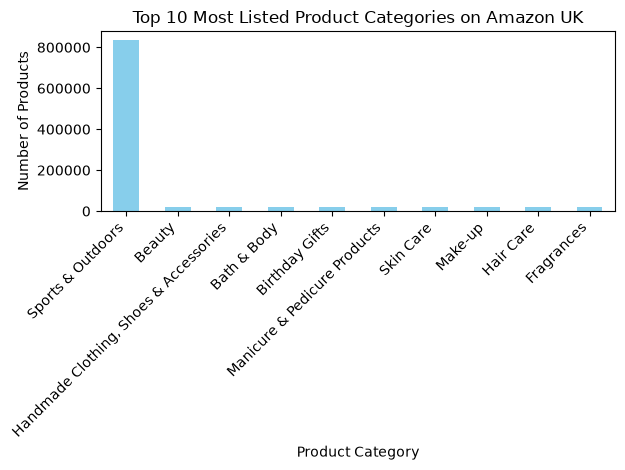

In [6]:
df_top_10.plot(kind="bar", color="skyblue")

plt.title("Top 10 Most Listed Product Categories on Amazon UK")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

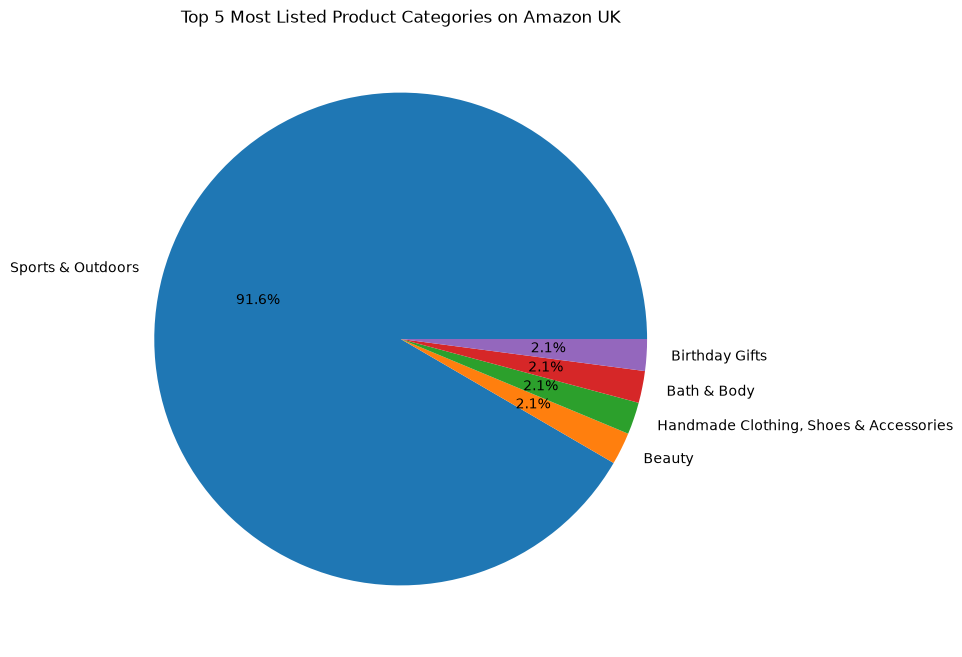

In [7]:
df_top_5.plot(kind="pie",autopct="%1.1f%%",figsize=(8, 8))

plt.title("Top 5 Most Listed Product Categories on Amazon UK")
plt.ylabel("")
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?



In [8]:
print("Mean price:", df["price"].mean())
print("Median price:", df["price"].median())
print("Mode price:", df["price"].mode().tolist())

Mean price: 89.24380943923661
Median price: 19.09
Mode price: [9.99]


The mean product price is 89.24, while the median is 19.09 and the mode is 9.99. 
The mean is considerably higher than the median, suggesting a right-skewed price distribution.
The mode indicates that £9.99 is the most frequently listed price.
Overall, the average price may not be representative of a typical product listing.

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [9]:

# Variance
print("Variance:", df["price"].var())

# Standard deviation
print("Standard Deviation:", df["price"].std())

#Range
print("Range:", df["price"].max() - df["price"].min())

# Interquartile range (IQR)
print("Q1:", df["price"].quantile(0.25))
print("Q3:", df["price"].quantile(0.75))
print("IQR:", df["price"].quantile(0.75) - df["price"].quantile(0.25))

Variance: 119445.48532254901
Standard Deviation: 345.60886175349873
Range: 100000.0
Q1: 9.99
Q3: 45.99
IQR: 36.0


Product prices show a significant spread, with a variance of 119,445.49, a standard deviation of 345.61, and a range of 100,000. The mean price (89.24) is considerably higher than the median (19.09), suggesting that a few extremely expensive products may be pulling the average upwards. However, the IQR of 36.00 indicates that the middle 50% of prices are more concentrated, between 9.99 and 45.99. Overall, the results suggest a highly right-skewed distribution with substantial variability, potentially influenced by extreme values.

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

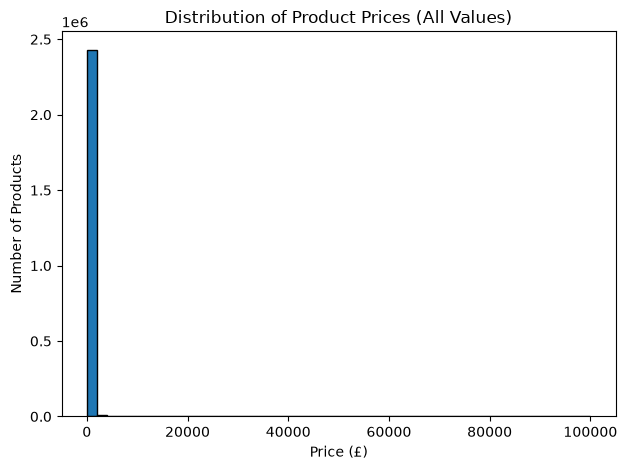

In [13]:
price_values = df["price"].dropna()

plt.hist(price_values, bins=50, edgecolor="black")

plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.title("Distribution of Product Prices (All Values)")
plt.tight_layout()
plt.show()

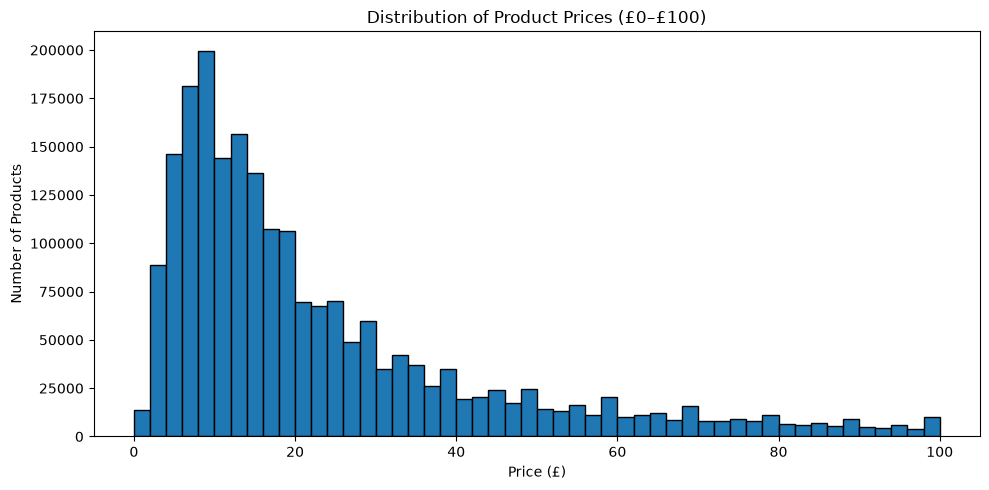

Products priced at £100 or less: 2,116,397 of 2,443,651 (86.61%).


In [14]:
plt.figure(figsize=(10, 5))

plt.hist(
    price_values[price_values <= 100],
    bins=50,
    edgecolor="black"
)

plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.title("Distribution of Product Prices (£0–£100)")
plt.tight_layout()
plt.show()

print(
    f"Products priced at £100 or less: "
    f"{(price_values <= 100).sum():,} of "
    f"{price_values.size:,} "
    f"({(price_values <= 100).mean() * 100:.2f}%)."
)

C:\Users\Raquel Marques\AppData\Local\Temp\ipykernel_25620\1375552539.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


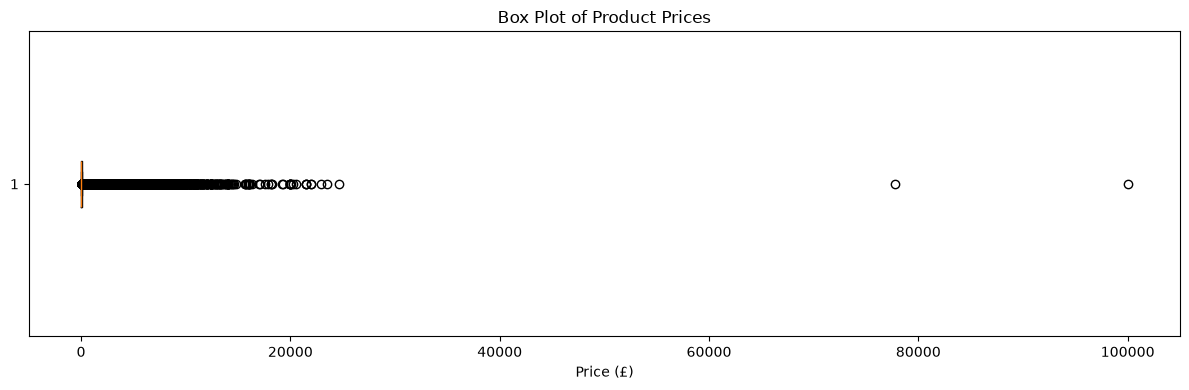

In [15]:
plt.figure(figsize=(12, 4))

plt.boxplot(
    df["price"].dropna(),
    vert=False,
    showfliers=True
)

plt.xlabel("Price (£)")
plt.title("Box Plot of Product Prices")
plt.tight_layout()
plt.show()

C:\Users\Raquel Marques\AppData\Local\Temp\ipykernel_25620\735439395.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


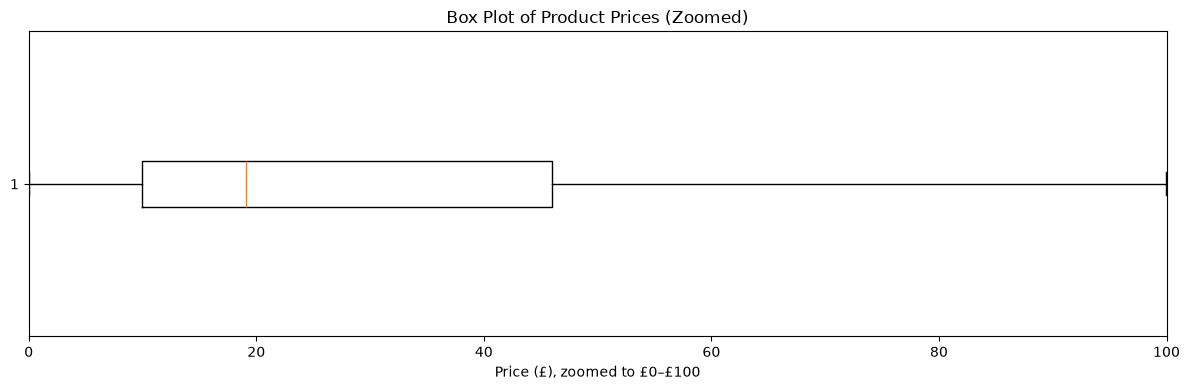

In [16]:
plt.figure(figsize=(12, 4))

plt.boxplot(
    df["price"].dropna(),
    vert=False,
    showfliers=False
)

plt.xlim(0, 100)
plt.xlabel("Price (£), zoomed to £0–£100")
plt.title("Box Plot of Product Prices (Zoomed)")
plt.tight_layout()
plt.show()

In [17]:
price_q1 = df["price"].quantile(0.25)
price_q3 = df["price"].quantile(0.75)
price_iqr = price_q3 - price_q1

lower_fence = price_q1 - 1.5 * price_iqr
upper_fence = price_q3 + 1.5 * price_iqr

price_outliers = df.loc[
    (df["price"] < lower_fence) |
    (df["price"] > upper_fence),
    "price"
]

print("Potential price outliers:", len(price_outliers))
print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)

print("Largest prices:")
print(df["price"].nlargest(10).to_string(index=False))

Potential price outliers: 327688
Lower fence: -44.01
Upper fence: 99.99000000000001
Largest prices:
100000.00
 77752.00
 24674.59
 23482.73
 22933.42
 21999.00
 21999.00
 21464.82
 21464.82
 21464.82


The histogram helps identify the price ranges containing the largest number of products. 
If the histogram using all prices is difficult to read. 
Limiting the visualisation to prices below £100 makes the more common price ranges easier to examine without removing products from the original dataset.
The box plot highlights potential outliers.
Products above the upper whisker may have unusually high prices compared with the rest of the dataset. 
These values should be investigated before deciding whether they represent genuine products or data quality issues.

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [19]:
rating = df["stars"].dropna()

rating_modes = rating.mode().tolist()

print("Mean rating:", rating.mean())
print("Median rating:", rating.median())
print("Mode rating(s):", rating_modes)

Mean rating: 2.152836472966066
Median rating: 0.0
Mode rating(s): [0.0]


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [20]:
rating_q1 = rating.quantile(0.25)
rating_q3 = rating.quantile(0.75)
rating_iqr = rating_q3 - rating_q1

print("Variance:", rating.var())
print("Standard deviation:", rating.std())
print("Q1:", rating_q1)
print("Q3:", rating_q3)
print("IQR:", rating_iqr)

Variance: 4.817434029796864
Standard deviation: 2.194865378513421
Q1: 0.0
Q3: 4.4
IQR: 4.4


3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [21]:
rating_skewness = rating.skew()
rating_kurtosis = rating.kurt()

print("Skewness:", rating_skewness)
print("Kurtosis (excess):", rating_kurtosis)

if rating_skewness > 0.5:
    print("Ratings are positively (right) skewed.")
elif rating_skewness < -0.5:
    print("Ratings are negatively (left) skewed.")
else:
    print("Ratings do not show strong skewness based on the ±0.5 rule of thumb.")

Skewness: 0.08120735761080881
Kurtosis (excess): -1.9260061280432994
Ratings do not show strong skewness based on the ±0.5 rule of thumb.


4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

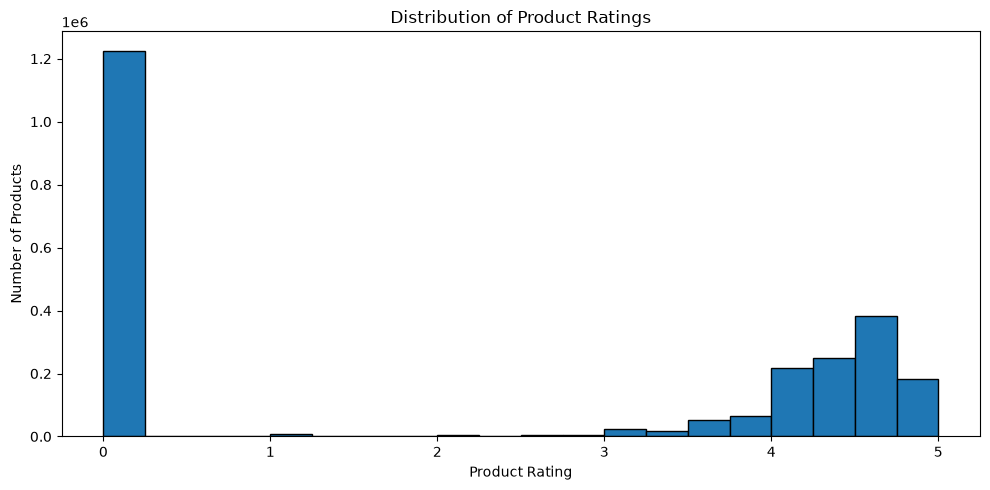

Most frequent rating(s): [0.0]


In [22]:
plt.figure(figsize=(10, 5))

plt.hist(rating, bins=20, edgecolor="black")

plt.xlabel("Product Rating")
plt.ylabel("Number of Products")
plt.title("Distribution of Product Ratings")
plt.tight_layout()
plt.show()

print("Most frequent rating(s):", rating_modes)